In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error,mean_squared_error


In [25]:
df = pd.read_csv("/home/havin-benoy/Desktop/Pyspiders/ml/Datasets/Salary_dataset.csv")

display(df.head())

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


In [26]:
df = df.drop(columns = "Unnamed: 0")

df.head(5)

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [28]:
print(df.corr())

                 YearsExperience    Salary
YearsExperience         1.000000  0.978242
Salary                  0.978242  1.000000


conclusion from the correlation matrix:
- The columns are having very high correlation (0.97 i.e very close to 1)
- Hence the data is linear and we can use linear regression.

In [29]:

x = df.drop(columns = "Salary")
y = df["Salary"]


In [30]:

x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=42)


In [31]:
model_lr = LinearRegression()

In [32]:
model_lr.fit(x_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[9423.82]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['YearsExperience']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.438e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [33]:

model_lr.intercept_

np.float64(24380.201479473704)

In [34]:
# Slope

model_lr.coef_

array([9423.81532303])

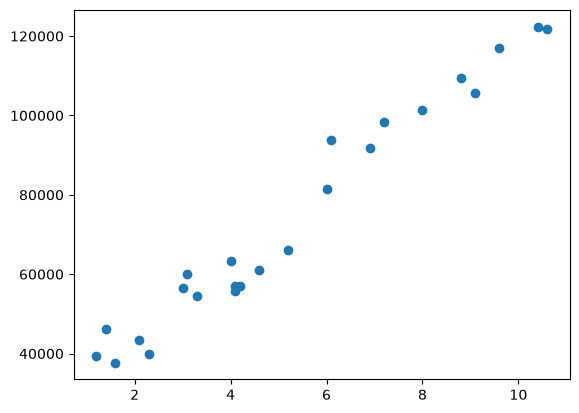

In [35]:
# Model Evaluation
plt.scatter(x_train,y_train)

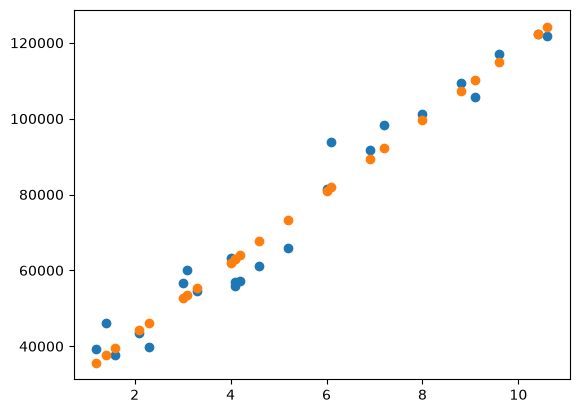

In [36]:

y_train_predicted = model_lr.predict(x_train)
plt.scatter(x_train,y_train)    # actual input vs actual output

plt.scatter(x_train,y_train_predicted)    # actual input vs predicted output

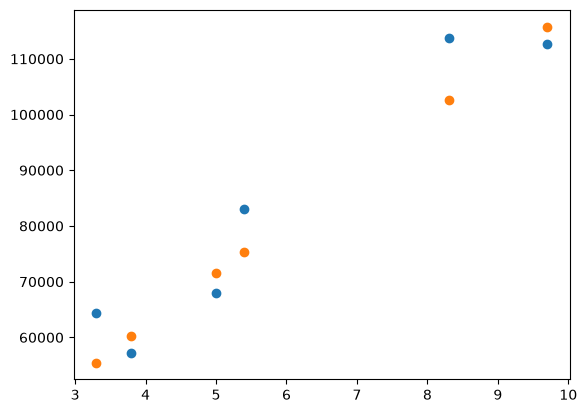

In [37]:

# Model Testing
y_test_predicted = model_lr.predict(x_test)
plt.scatter(x_test,y_test)    # actual input vs actual output

plt.scatter(x_test,y_test_predicted)    # actual input vs predicted output



# Regression Evaluation metrics

1. Mean Squared Error (MSE)
2. Root Mean Squared Error (RMSE)
3. Mean Absolute Error (MAE)
4. r^2 score


In [38]:
# 4. r2 score

train_r2_score =r2_score(y_train,y_train_predicted)

test_r2_score= r2_score(y_test,y_test_predicted)


print(train_r2_score, test_r2_score)

0.9645401573418148 0.9024461774180497


In [39]:
# 3. Mean Absolute Error (MAE)

train_mae =mean_absolute_error(y_train,y_train_predicted)

test_mae = mean_absolute_error(y_test,y_test_predicted)


print(train_mae, test_mae)

4221.046734449735 6286.453830757745


In [40]:
# 2. Root Mean Squared Error (RMSE)

train_rmse =root_mean_squared_error(y_train,y_train_predicted)

test_rmse = root_mean_squared_error(y_test,y_test_predicted)


print(train_rmse, test_rmse)

5205.982110155713 7059.04362190151


In [41]:
# Error percentage based on the MAE .

# To check if an mae value is high or not we should use it to calculate the error percentage
#  error percentage based on mae equation is : (average(y_train) / mae )* 100

avg_of_y_train = sum(y_train)/len(y_train)

print("Average of Y train: ",avg_of_y_train)

error_percentage_based_on_mae = (avg_of_y_train/train_mae)*100

print("Error percentage based on mae: ",error_percentage_based_on_mae)

Average of Y train:  74208.625
Error percentage based on mae:  1758.0621506592724


In [42]:
# 1. Mean Squared Error (MSE)

train_mse = mean_squared_error(y_train,y_train_predicted)

test_mse = mean_squared_error(y_test,y_test_predicted)


print(train_mse, test_mse)

27102249.73126133 49830096.855908394


##Final conclusion:
- r2_score is very high for both train and test splits.
- That means the model understood the internal pattern in the data and will perform well on the unseen future data as well.
- The reason for this that the data is linear data and the linear regression model was able to capture linear data pattern.

